# 09 · Label convention: water vs land in mixed images

**Hypothesis:** EuroSAT and the Kaggle set might label mixed images differently. An image with some water and some
vegetation could be *River* in EuroSAT but a vegetation class on Kaggle (or the other way around). The model
would then be right by EuroSAT's rule and still be scored wrong.

The Kaggle labels are hidden, so this notebook can only check the parts that need no labels:

1. **EuroSAT's rule:** which label does EuroSAT give at which water share?
2. **The model on Kaggle:** does the best model (`E09a` + AdaBN, 71.78%) follow that rule on Kaggle images?
3. **Where a different convention could hide:** which groups of Kaggle images would change, and how many.
4. **Probe files:** submissions that switch only one group to the model's second choice. A higher public score
   would show that Kaggle labels that group differently (submitted 2026-10-24, results in section 7).

**Water measure:** share of pixels with NIR (B08) < `WATER_NIR`, on **raw** images of both datasets. Section 2
shows why not NDWI: the haze removal in the Kaggle images lowers the green band so much that dark water often has
NDWI < 0 there (and the same happens to EuroSAT after `hist_split`).

## 1 · Setup and data

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, band_index, load_test, load_train
from src.experiment import find_run, load_correction
from src.plot_style import apply_style
from src.training import load_run, predict_views, to_device_images
from src.utils import get_device

apply_style()
device = get_device()

# ---- Settings --------------------------------------------------------------------------
MAIN_RUN = "adabn_balanced_pl_r3_view_agree_contrast_aug_hist_split_effb0"   # E09a + AdaBN, 71.78%
WATER_NIR = 800                                                # water pixel: B08 below this
WATER_BINS = [0, 0.02, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
WATER_CLASSES = ["River", "SeaLake"]
VEG = ["AnnualCrop", "PermanentCrop", "Pasture", "HerbaceousVegetation", "Forest"]
CHUNK = 2000
SEED = 0

X_all, meta = load_train()
X_kg, test_ids = load_test()
X_kg = np.asarray(X_kg)
labels = meta["label"].values
print(f"Kaggle {len(X_kg):,} images, EuroSAT {len(X_all):,} images")

Kaggle 4,232 images, EuroSAT 27,000 images


In [2]:
def band(X, name):
    return X[:, band_index(name)].astype(np.float32)


def water_share(X):
    return (band(X, "B08") < WATER_NIR).mean(axis=(1, 2))


def ndwi_share(X):
    g, nir = band(X, "B03"), band(X, "B08")
    return ((g - nir) / (g + nir + 1e-6) > 0).mean(axis=(1, 2))


hist_split = load_correction("hist_split")
parts = []
for s in range(0, len(X_all), CHUNK):
    xb = np.asarray(X_all[s:s + CHUNK])
    parts.append(pd.DataFrame({"water": water_share(xb), "ndwi": ndwi_share(xb),
                               "ndwi_hist_split": ndwi_share(hist_split(xb))}))
eu = pd.concat(parts, ignore_index=True).assign(label=labels)
kg = pd.DataFrame({"water": water_share(X_kg), "ndwi": ndwi_share(X_kg)})
water_bin = lambda w: pd.cut(w, WATER_BINS, include_lowest=True)

## 2 · Which water measure is comparable?

Water pixels are bimodal in NIR (very dark), and B08 changes little between the datasets (test/train ratio ~0.9),
while B03 drops to 0.61 on Kaggle. A fixed NIR threshold therefore means the same in both datasets; NDWI does
not. Checks: share of River/SeaLake images that a measure calls (almost) dry, and images the model calls River
that NDWI calls dry.

In [3]:
def checks(df, col, label_col):
    return {"mean water share": df[col].mean(),
            "River with ≤ 2% water": (df.loc[df[label_col] == "River", col] <= 0.02).mean(),
            "SeaLake with ≤ 2% water": (df.loc[df[label_col] == "SeaLake", col] <= 0.02).mean()}


CHECKS = {("EuroSAT raw (labels)", "NDWI > 0"): (eu, "ndwi", "label"),
          ("EuroSAT raw (labels)", f"B08 < {WATER_NIR}"): (eu, "water", "label"),
          ("EuroSAT hist_split (labels)", "NDWI > 0"): (eu, "ndwi_hist_split", "label")}
water_checks = pd.DataFrame({k: checks(*v) for k, v in CHECKS.items()})
water_checks

EuroSAT raw (labels)            \
                                    NDWI > 0 B08 < 800   
mean water share                    0.149317  0.138899   
River with ≤ 2% water               0.014800  0.054000   
SeaLake with ≤ 2% water             0.000333  0.015000   

                        EuroSAT hist_split (labels)  
                                           NDWI > 0  
mean water share                           0.122287  
River with ≤ 2% water                      0.226000  
SeaLake with ≤ 2% water                    0.046000

## 3 · EuroSAT's rule: label by water share

Counts of the true EuroSAT labels per water-share bin (raw images), and the same as a share of each bin.

In [4]:
eu_tab = pd.crosstab(water_bin(eu["water"]), eu["label"]).reindex(columns=CLASSES, fill_value=0)
eu_tab.assign(total=eu_tab.sum(axis=1))

label,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake,total
water,,,,,,,,,,,
"(-0.001, 0.02]",2987,2977,2667,2211,1859,1971,2473,2702,135,45,20027
"(0.02, 0.1]",4,21,173,206,470,25,23,215,249,6,1392
"(0.1, 0.3]",4,2,108,71,159,4,4,72,1022,10,1456
"(0.3, 0.5]",3,0,42,10,11,0,0,9,776,8,859
"(0.5, 0.7]",2,0,9,1,1,0,0,2,302,26,343
"(0.7, 0.9]",0,0,1,1,0,0,0,0,16,289,307
"(0.9, 1.0]",0,0,0,0,0,0,0,0,0,2616,2616


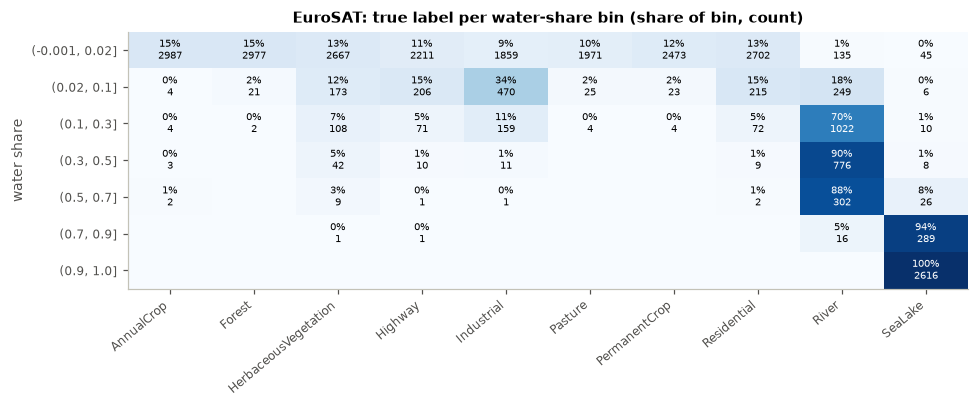

In [5]:
def heat(tab, title, ax):
    share = tab.div(tab.sum(axis=1), axis=0)
    ax.imshow(share.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for (r, c), v in np.ndenumerate(share.values):
        if tab.values[r, c]:
            ax.text(c, r, f"{v:.0%}\n{tab.values[r, c]}", ha="center", va="center", fontsize=6.5,
                    color="white" if v > 0.6 else "black")
    ax.set_xticks(range(len(tab.columns)), tab.columns, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(tab.index)), [str(i) for i in tab.index], fontsize=8)
    ax.set_title(title, fontsize=10); ax.grid(False)


fig, ax = plt.subplots(figsize=(9, 3.8))
heat(eu_tab, "EuroSAT: true label per water-share bin (share of bin, count)", ax)
ax.set_ylabel("water share")
plt.tight_layout(); plt.show()

## 4 · The model on Kaggle: same table with predictions

Predictions of `E09a` + AdaBN (8-view TTA). If the model follows EuroSAT's rule, both tables have the same shape;
the *number* of images per bin can differ (Kaggle has much more open water).

loaded runs/2026-10-15_1830_adabn_balanced_pl_r3_view_agree_contrast_aug_hist_split_effb0


EuroSAT raw (labels)            \
                                    NDWI > 0 B08 < 800   
mean water share                       0.149     0.139   
River with ≤ 2% water                  0.015     0.054   
SeaLake with ≤ 2% water                0.000     0.015   

                        EuroSAT hist_split (labels) Kaggle raw (predicted)  \
                                           NDWI > 0               NDWI > 0   
mean water share                              0.122                  0.259   
River with ≤ 2% water                         0.226                  0.227   
SeaLake with ≤ 2% water                       0.046                  0.000   

                                   
                        B08 < 800  
mean water share            0.264  
River with ≤ 2% water       0.035  
SeaLake with ≤ 2% water     0.000

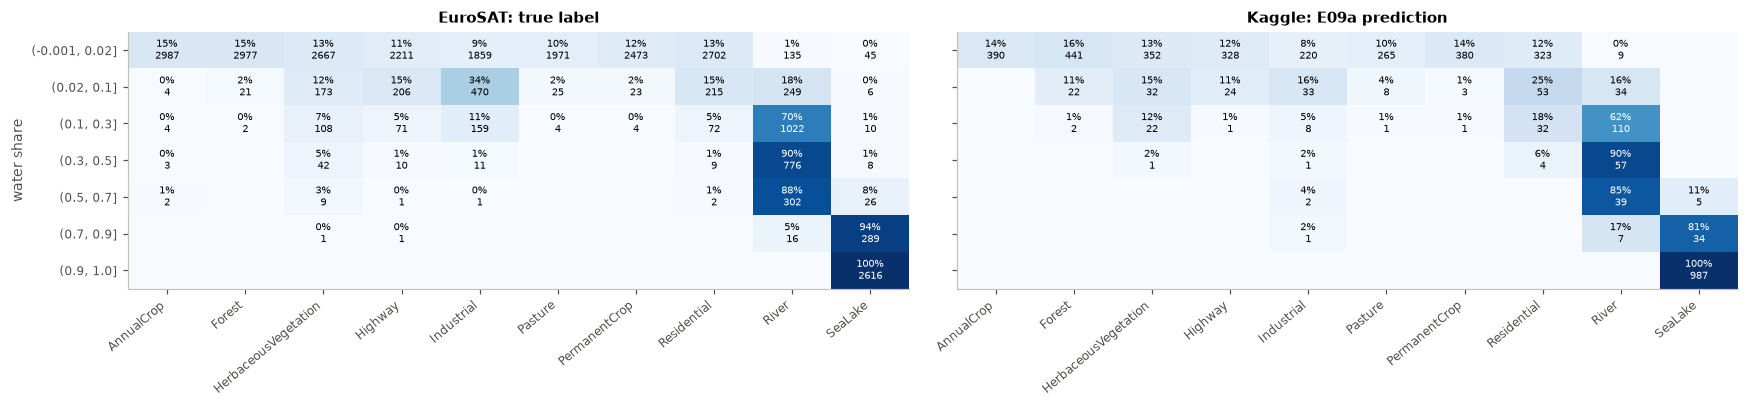

In [6]:
run_dir = find_run(MAIN_RUN)
model, normalizer, _ = load_run(run_dir, device)
print("loaded", run_dir.relative_to(PROJECT_ROOT))
prob = predict_views(model, to_device_images(X_kg, device), normalizer).mean(0)
order = np.argsort(-prob, axis=1)
kg = kg.assign(pred=np.array(CLASSES)[order[:, 0]], second=np.array(CLASSES)[order[:, 1]],
               conf=prob.max(1), p_second=np.take_along_axis(prob, order[:, 1:2], 1)[:, 0])

for col, name in [("ndwi", "NDWI > 0"), ("water", f"B08 < {WATER_NIR}")]:
    water_checks[("Kaggle raw (predicted)", name)] = checks(kg, col, "pred")
display(water_checks.round(3))

kg_tab = pd.crosstab(water_bin(kg["water"]), kg["pred"]).reindex(columns=CLASSES, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), sharey=True)
heat(eu_tab, "EuroSAT: true label", axes[0])
heat(kg_tab, "Kaggle: E09a prediction", axes[1])
axes[0].set_ylabel("water share")
plt.tight_layout(); plt.show()

Compact comparison per bin: share of images that are water classes (River/SeaLake), vegetation classes, and
built-up classes (Highway/Industrial/Residential), EuroSAT labels vs Kaggle predictions.

In [7]:
GROUPS = {"water": WATER_CLASSES, "vegetation": VEG, "built-up": ["Highway", "Industrial", "Residential"]}


def group_share(tab):
    share = tab.div(tab.sum(axis=1), axis=0)
    return pd.DataFrame({g: share[c].sum(axis=1) for g, c in GROUPS.items()}).assign(images=tab.sum(axis=1))


pd.concat({"EuroSAT (labels)": group_share(eu_tab), "Kaggle (predicted)": group_share(kg_tab)}, axis=1).round(3)

EuroSAT (labels)                            Kaggle (predicted)  \
                          water vegetation built-up images              water   
water                                                                           
(-0.001, 0.02]            0.009      0.653    0.338  20027              0.003   
(0.02, 0.1]               0.183      0.177    0.640   1392              0.163   
(0.1, 0.3]                0.709      0.084    0.207   1456              0.621   
(0.3, 0.5]                0.913      0.052    0.035    859              0.905   
(0.5, 0.7]                0.956      0.032    0.012    343              0.957   
(0.7, 0.9]                0.993      0.003    0.003    307              0.976   
(0.9, 1.0]                1.000      0.000    0.000   2616              1.000   

                                           
               vegetation built-up images  
water                                      
(-0.001, 0.02]      0.675    0.322   2708  
(0.02, 0.1]         0.311    0.526    209  
(0.1, 0.3]          0.147    0.232    177  
(0.3, 0.5]          0.016    0.079     63  
(0.5, 0.7]          0.000    0.043     46  
(0.7, 0.9]          0.000    0.024     42  
(0.9, 1.0]          0.000    0.000    987

## 5 · Look at the groups that could carry a different convention

The candidate groups from the tables:

- **River with (almost) no water** (≤ 2%): almost never in EuroSAT, but the model predicts it on Kaggle.
- **River with some water** (10–30%), second choice vegetation: the classic mixed scene. EuroSAT calls these River.
- **Vegetation predicted although there is water** (> 2%): the other direction.

Images: top row true colour, bottom row false colour (B08/B04/B03: vegetation red, water black), fixed stretch.

In [8]:
rng = np.random.default_rng(SEED)


def show_grid(X, idx, titles, suptitle, n=10):
    fig, axes = plt.subplots(2, n, figsize=(n * 1.45, 3.4))
    for k in range(n):
        for r, (bands, scale) in enumerate([(["B04", "B03", "B02"], 1500), (["B08", "B04", "B03"], 3500)]):
            ax = axes[r, k]
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if k >= len(idx):
                ax.axis("off"); continue
            img = np.stack([X[idx[k], band_index(b)] for b in bands], -1).astype(np.float32)
            ax.imshow(np.clip(img / scale, 0, 1) ** 0.8)
            if r == 0:
                ax.set_title(titles[k], fontsize=7)
    axes[0, 0].set_ylabel("RGB", fontsize=8); axes[1, 0].set_ylabel("NIR-R-G", fontsize=8)
    fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout()
    plt.show()


def sample(mask, n=10):
    idx = np.flatnonzero(mask)
    return np.sort(rng.choice(idx, min(n, len(idx)), replace=False))


river = kg["pred"] == "River"
CANDIDATES = {
    "A · River, ≤ 2% water": river & (kg["water"] <= 0.02),
    "B · River, 10–30% water, 2nd = vegetation": river & kg["water"].between(0.1, 0.3) & kg["second"].isin(VEG),
    "C · vegetation, > 2% water": kg["pred"].isin(VEG) & (kg["water"] > 0.02),
}
pd.DataFrame({name: {"images": int(m.sum()), "share of Kaggle": m.mean(), "mean confidence": kg.loc[m, "conf"].mean(),
                     "most common 2nd choice": kg.loc[m, "second"].mode().iat[0] if m.any() else ""}
              for name, m in CANDIDATES.items()}).T

,images,share of Kaggle,mean confidence,most common 2nd choice
"A · River, ≤ 2% water",9,0.002127,0.785109,AnnualCrop
"B · River, 10–30% water, 2nd = vegetation",46,0.01087,0.854403,HerbaceousVegetation
"C · vegetation, > 2% water",92,0.021739,0.80472,River


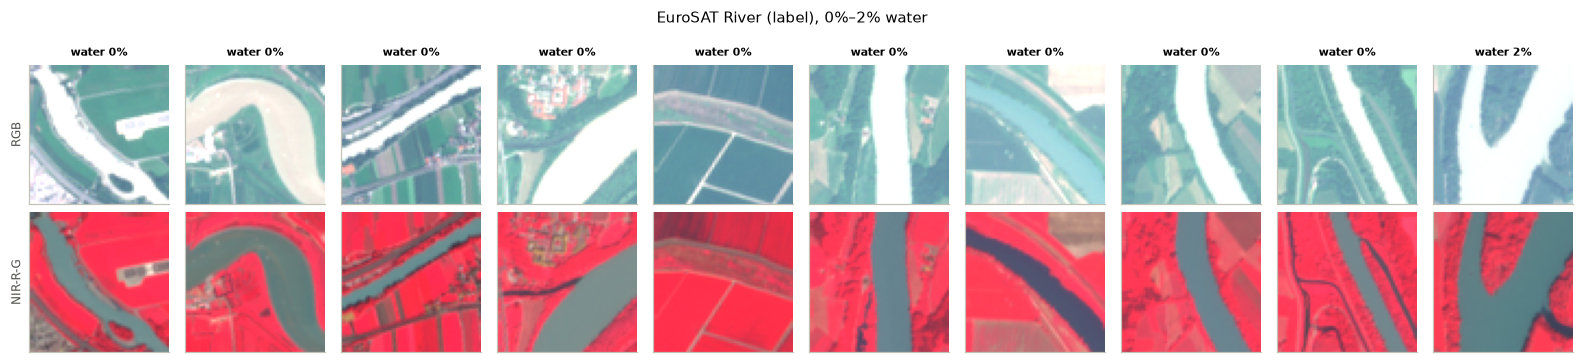

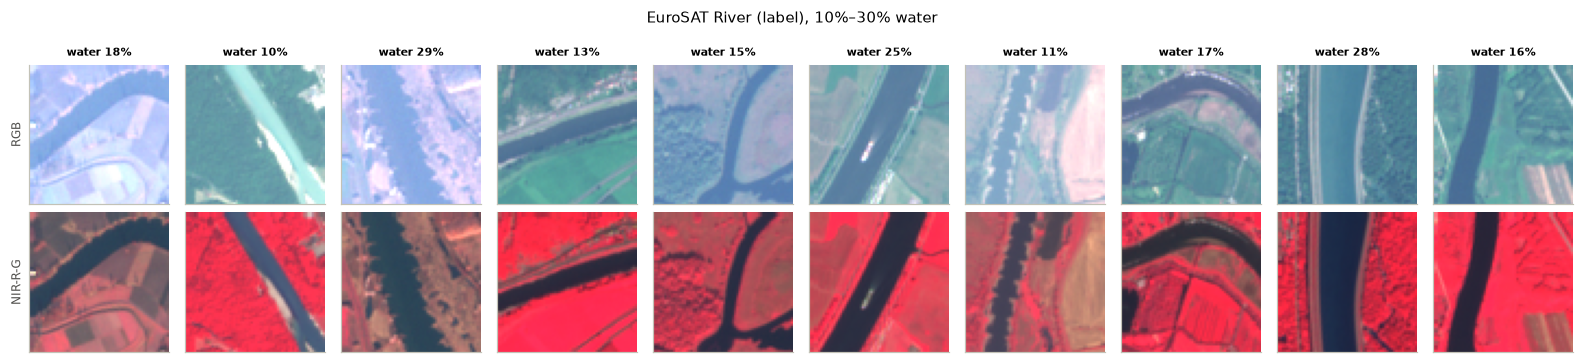

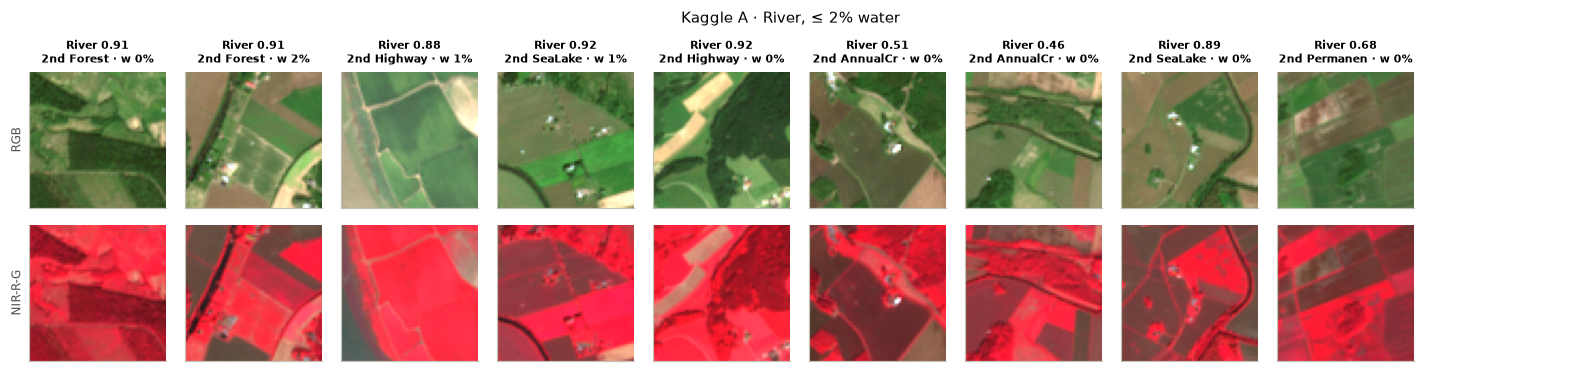

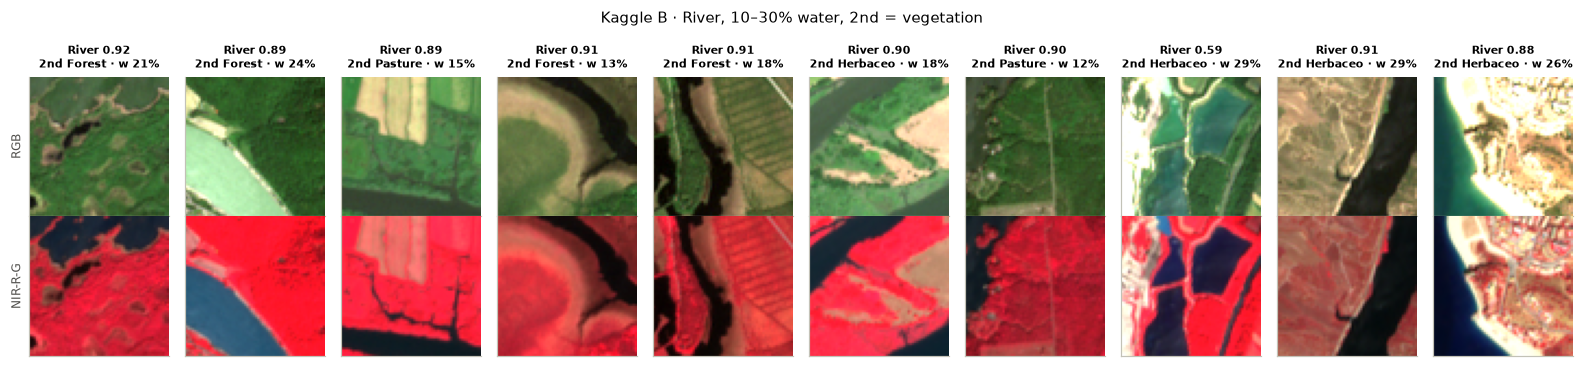

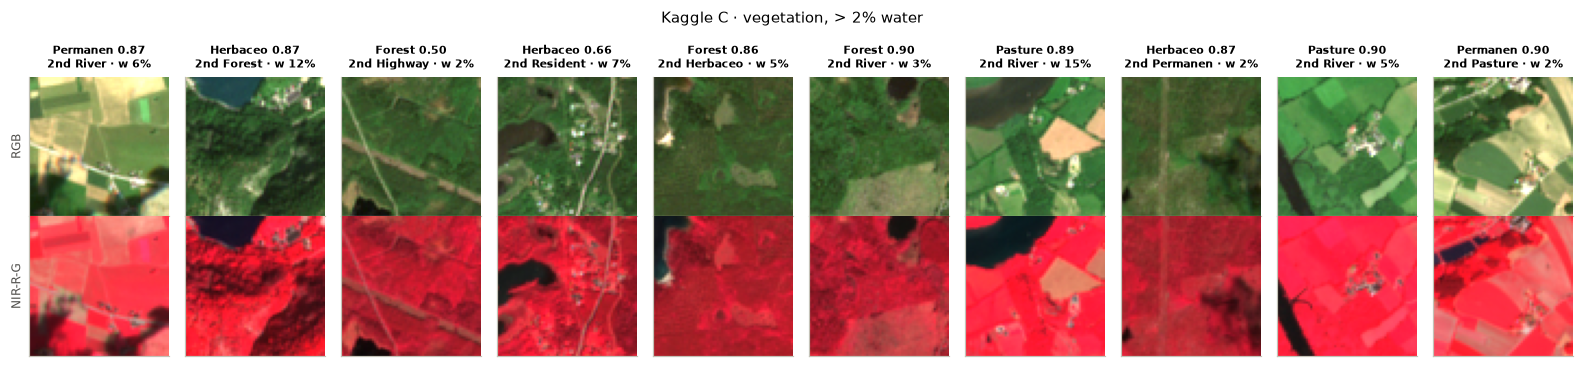

In [9]:
X_eu_river = np.asarray(X_all[np.flatnonzero(labels == "River")])
eu_river = eu[eu.label == "River"].reset_index(drop=True)
for lo, hi in [(0, 0.02), (0.1, 0.3)]:
    idx = sample(eu_river["water"].between(lo, hi))
    show_grid(X_eu_river, idx, [f"water {eu_river['water'][i]:.0%}" for i in idx],
              f"EuroSAT River (label), {lo:.0%}–{hi:.0%} water")
for name, m in CANDIDATES.items():
    idx = sample(m)
    show_grid(X_kg, idx, [f"{kg['pred'][i][:8]} {kg['conf'][i]:.2f}\n2nd {kg['second'][i][:8]} · w {kg['water'][i]:.0%}"
                          for i in idx], f"Kaggle {name}")

## 6 · Probe files (not submitted)

Each file is the `E09a` + AdaBN submission with **only one group** switched to the model's second choice.
Expected change of the public score if Kaggle labels the whole group differently: up to about
group size / number of test images (only the public part of the group counts).
They are leaderboard probes: the result is used to decide about the *training labels*, never to hand-edit the
final predictions. Scores in section 7.

In [10]:
PROBE_DIR = PROJECT_ROOT / "artifacts" / "probes"
PROBE_DIR.mkdir(parents=True, exist_ok=True)
base = pd.read_csv(run_dir / "submission.csv")
assert (base["label"].values == kg["pred"].values).all(), "submission.csv differs from the recomputed predictions"
rows = {}
for name, m in CANDIDATES.items():
    sub = base.copy()
    sub.loc[m.values, "label"] = kg.loc[m, "second"].values
    path = PROBE_DIR / f"probe_{name[0]}_{MAIN_RUN}.csv"
    sub.to_csv(path, index=False)
    rows[name] = {"switched": int(m.sum()), "max score change": m.sum() / len(kg),
                  "file": str(path.relative_to(PROJECT_ROOT))}
pd.DataFrame(rows).T

,switched,max score change,file
"A · River, ≤ 2% water",9,0.002127,artifacts/probes/probe_A_adabn_balanced_pl_r3_...
"B · River, 10–30% water, 2nd = vegetation",46,0.01087,artifacts/probes/probe_B_adabn_balanced_pl_r3_...
"C · vegetation, > 2% water",92,0.021739,artifacts/probes/probe_C_adabn_balanced_pl_r3_...


## 7 · Conclusion

**Water measure**

- **NDWI is not comparable across the datasets.** On Kaggle, 22.7% of the images the model calls River have ≤ 2%
  NDWI water, and the grids show plain rivers. The haze removal lowers B03 so far that dark water gets NDWI < 0.
  `hist_split` does the same to EuroSAT (22.6% of River images look dry). NIR < 800 behaves the same in both
  datasets (River with ≤ 2% water: EuroSAT 5.4%, Kaggle 3.5%). Section 3 of `08_vegetation_shift` and its CSV
  use NDWI, so its `water_px` undercounts water on Kaggle.
- NIR < 800 also catches cloud and forest shadows (visible in group C), so a small "water" share is not proof of water.

**Label convention**

- **The model already follows EuroSAT's water rule on Kaggle.** Per water-share bin, the water/vegetation/built-up
  mix of the predictions is within a few points of EuroSAT's labels (10–30% water: 62% vs 70% water classes;
  ≥ 30%: 90–100% in both). SeaLake starts at ~70% water in both.
- **The mixed zone is small.** Only ~12% of the Kaggle images have 2–70% water. The groups where a different
  convention could hide are A (9 images), B (46) and C (92, partly shadows). Together that is at most ~3.5% of the
  test set, and only if Kaggle labels *all* of them the other way. It cannot explain most of the ~28% gap.
- **Most errors are elsewhere:** 64% of the Kaggle images have no water at all, and that is where the uncertain
  vegetation pairs from `06_kaggle_confidence` / `08_vegetation_shift` are.

**Probe results (Kaggle public score, submitted 2026-10-24; baseline E09a + AdaBN 0.71782)**

The public part has ~2,116 images, so one image ≈ 0.00047. Net change = images the 2nd choice gets right minus
images the 1st choice got right (only the ~half of each group that is in the public part counts).

| Probe | switched | public score | change | net images |
|---|---|---|---|---|
| A · River, ≤ 2% water → 2nd choice | 9 | 0.71829 | +0.00047 | +1 (noise) |
| B · River, 10–30% water → vegetation | 46 | 0.71174 | −0.00608 | **−13** of ~23 |
| C · vegetation, > 2% water → 2nd choice | 92 | 0.71548 | −0.00234 | −5 of ~46 |

- **The hypothesis is rejected.** Kaggle labels mixed river/vegetation scenes as **River**, like EuroSAT. Switching
  B lost about 13 of the ~23 public images, so the model's River predictions there are mostly right.
- C also gets worse: vegetation with a bit of water (or shadow) is labelled vegetation on Kaggle too.
- A: one image, within noise. Not worth changing anything.
- **No retraining with changed water/vegetation labels.** The gap is in the images without water (vegetation
  pairs, see `06_kaggle_confidence` / `08_vegetation_shift`).
